In [353]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from datetime import datetime as dt

# The Overall Data
There are a total of 4,374 entries in this dataset. Originally, this dataset has X,XXX entries but XXX did not had one or two birthdates missing, therefore, are not going to be considered for this dataset and interpretation.

In [2]:
divorce = pd.read_csv("data_pandas.csv")
divorce.head()
divorce.info()

<class 'pandas.DataFrame'>
RangeIndex: 4374 entries, 0 to 4373
Data columns (total 50 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Divorce_date                          4374 non-null   str    
 1   Type_of_divorce                       4374 non-null   str    
 2   Nationality_partner_man               4374 non-null   str    
 3   DOB_partner_man                       4374 non-null   str    
 4   Place_of_birth_partner_man            4369 non-null   str    
 5   Birth_municipality_of_partner_man     4366 non-null   str    
 6   Birth_federal_partner_man             4367 non-null   str    
 7   Birth_country_partner_man             4368 non-null   str    
 8   Age_partner_man                       4374 non-null   float64
 9   Residence_municipality_partner_man    4238 non-null   str    
 10  Residence_federal_partner_man         4239 non-null   str    
 11  Residence_country_partner_ma

In [278]:
len(divorce)

4374

In [69]:
# Converting 'combo_couple' as a categorical variable
cols = divorce.select_dtypes(include=['object']).columns
divorce["combo_couple"] = divorce["combo_couple"].astype('category')

/var/folders/th/cy__chcj5wgbf_w94b8zbqsm0000gn/T/ipykernel_41699/806669291.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = divorce.select_dtypes(include=['object']).columns


In [344]:
unique_astro_list = divorce['combo_couple'].cat.categories.tolist()

In [347]:
divorce4=divorce.copy()

In [348]:
def date_subtract(data,check_date,start_date,end_date):
    data[start_date] = pd.to_datetime(data[start_date], format='%d/%m/%y', dayfirst=True)
    data[end_date] = pd.to_datetime(data[end_date], format='%d/%m/%y', dayfirst=True)
    data['actual_years'] = (data[end_date] - data[start_date]) // pd.Timedelta(days=365.25)
    data['is_accurate'] = data['actual_years'].round().astype(int) == data[check_date]
    return data['is_accurate']


In [349]:
date_subtract(divorce4,'Marriage_duration','Date_of_marriage','Divorce_date')

0        True
1       False
2        True
3        True
4        True
        ...  
4369    False
4370     True
4371     True
4372     True
4373     True
Name: is_accurate, Length: 4374, dtype: bool

In [350]:
#Replace innaccurate rows
divorce4.loc[date_subtract(divorce4,'Marriage_duration','Date_of_marriage','Divorce_date') == False, 'Marriage_duration'] = divorce4['actual_years']

In [351]:
divorce4['Marriage_duration']

0        5.0
1       29.0
2        7.0
3       11.0
4       15.0
        ... 
4369     4.0
4370     1.0
4371    35.0
4372    33.0
4373     4.0
Name: Marriage_duration, Length: 4374, dtype: float64

In [356]:
#divorce4['DOB_partner_man'] = np.where(df['date'].dt.year > 2024, df['date'] - pd.DateOffset(years=100), df['date'])

# Star Signs vs. Duration of Marriage
### Top 5 Longest Marriages and Top 5 Shortest Marriages
I have before created a column called `combo_couple`, which takes in both `Sign_Woman` and `Sign_Man`, this helps create more data points for each star sign duos and disregards gender.

In [61]:
all_mean=divorce.groupby("combo_couple")['Marriage_duration'].mean()
all_mean.sort_values(ascending=False)

combo_couple
('Pisces', 'Capicorn')            15.777778
('Libra', 'Pisces')               14.730769
('Sagittarius', 'Sagittarius')    14.264706
('Capicorn', 'Cancer')            14.095238
('Sagittarius', 'Pisces')         14.000000
                                    ...    
('Aires', 'Pisces')                7.937500
('Cancer', 'Capicorn')             7.900000
('Scorpio', 'Leo')                 7.846154
('Pisces', 'Aquarius')             7.828571
('Cancer', 'Virgo')                7.703704
Name: Marriage_duration, Length: 144, dtype: float64

In [62]:
all_med=divorce.groupby("combo_couple")['Marriage_duration'].median()
all_med.sort_values(ascending=False)

combo_couple
('Pisces', 'Capicorn')            14.0
('Capicorn', 'Cancer')            13.0
('Taurus', 'Scorpio')             13.0
('Sagittarius', 'Sagittarius')    13.0
('Cancer', 'Sagittarius')         12.5
                                  ... 
('Aquarius', 'Cancer')             6.0
('Pisces', 'Aquarius')             6.0
('Libra', 'Sagittarius')           5.5
('Sagittarius', 'Libra')           5.0
('Aires', 'Scorpio')               5.0
Name: Marriage_duration, Length: 144, dtype: float64

In [63]:
overall_mean=divorce['Marriage_duration'].mean()
overall_mean

np.float64(11.184086629001884)

## Pisces and Capicorn (Permuting the Mean)
Pisces and Capicorn in the Divorce Data overall had the longest marriage duration based on mean and median, so we are going to filter all Pisces and Capicorn data and create more data points by bootstrapping the data to see if the average marriage duration is relevent (as there is only 27 data points)

In [64]:
divorce_PC=divorce.copy()
Dicorce_P_C=divorce_PC[divorce_PC['combo_couple']=="('Pisces', 'Capicorn')"]

In [24]:
PC_Mean=Dicorce_P_C['Marriage_duration'].mean()

In [25]:
replicates = [PC_Mean]

for _ in range(1_000) : 
    replicates.append(Dicorce_P_C.sample(frac=1, replace=True)['Marriage_duration'].mean())

In [155]:
#boot_mean=np.mean(replicates)

In [27]:
np.random.choice(replicates)

np.float64(15.185185185185185)

In [28]:
stored=[PC_Mean]

for _ in range(9999):
    diff=np.random.choice(replicates)
    stored.append(diff)

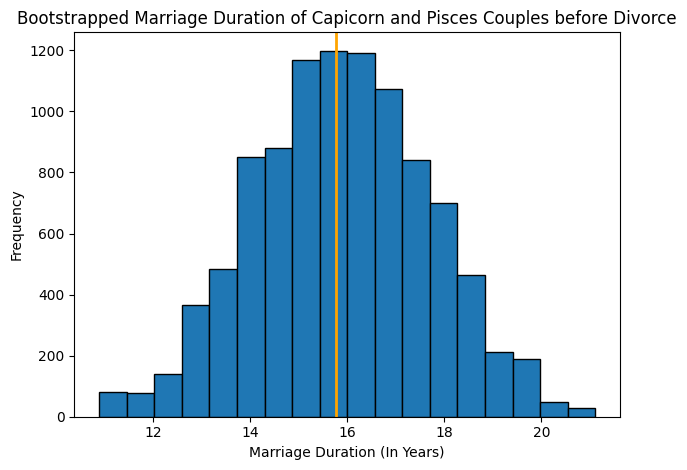

In [29]:
plt.hist(stored, bins=18, edgecolor='black')
plt.axvline(PC_Mean, color='orange', linestyle='-', linewidth=2)
plt.xlabel('Marriage Duration (In Years)')
plt.ylabel('Frequency')
plt.title('Bootstrapped Marriage Duration of Capicorn and Pisces Couples before Divorce')
plt.tight_layout()
plt.show()

In [30]:
replicates2=np.array(stored)
(abs(replicates2) >= abs(PC_Mean)).mean()

np.float64(0.5351)

## Is there Literally Anything Statically Significant?
We found the P Value of Capicorn and Pisces Couples and how many years they stayed married providided no statiscal significance. Let's find out if the other 143 star sign duos may provide statiscal significance.

In [37]:
divorce_copy=divorce.copy()
#Make it a function????
def test_star_dur(star_sign_duo):
    #filter
    Dicorce_bystar=divorce_copy[divorce_copy['combo_couple']==star_sign_duo]
    div_Mean=Dicorce_bystar['Marriage_duration'].mean()
    #bootstrapping, 1,000 more points
    replicates = [div_Mean]
    for _ in range(1_000) : 
        replicates.append(Dicorce_bystar.sample(frac=1, replace=True)['Marriage_duration'].mean())
    #Perm test
    stored=[div_Mean]
    for _ in range(9999):
        diff=np.random.choice(replicates)
        stored.append(diff)
    #P Value
    replicates3=np.array(stored)
    rep_pval=(abs(replicates3) >= abs(div_Mean)).mean()
    stored.clear
    replicates.clear
    return [star_sign_duo,div_Mean,rep_pval]

In [ ]:
s_col = ['Star Sign Duo', 'Average Marriage Duration (yrs)', 'P Value']
Overview_astro = pd.DataFrame(columns=s_col)

In [80]:
for i in unique_astro_list:
    new_row=test_star_dur(i)
    Overview_astro.loc[len(Overview_astro)] = new_row

In [87]:
Overview_astro.sort_values(by='P Value',ascending=True)

,Star Sign Duo,Average Marriage Duration,P Value
35,"('Cancer', 'Virgo')",7.703704,0.4422
130,"('Taurus', 'Taurus')",10.933333,0.4540
11,"('Aires', 'Virgo')",11.233333,0.4604
109,"('Scorpio', 'Aquarius')",12.419355,0.4605
83,"('Libra', 'Virgo')",9.916667,0.4620
...,...,...,...
113,"('Scorpio', 'Leo')",7.846154,0.5229
21,"('Aquarius', 'Scorpio')",11.655172,0.5237
96,"('Sagittarius', 'Aires')",9.500000,0.5294
30,"('Cancer', 'Libra')",13.193548,0.5315


...nope, no statiscal significance. The P Values are way over 0.05, even way over 0.1.

# Is Age Just a Number?

In [111]:
divorce2=divorce.copy()
divorce2['Age_Diff']=divorce2['Age_partner_man']-divorce2['Age_partner_woman']

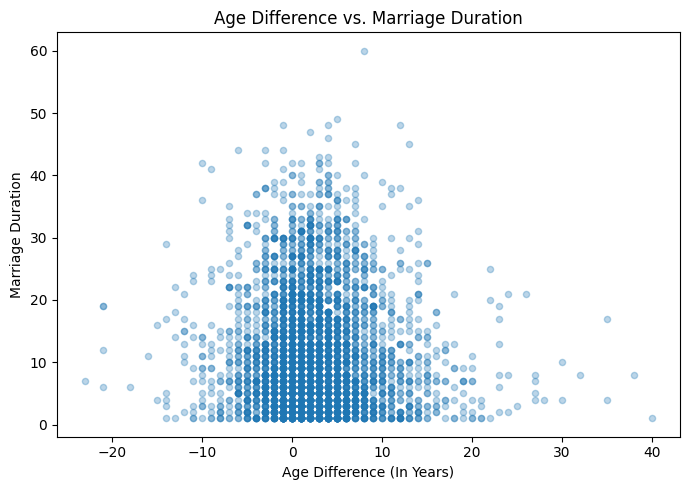

In [113]:
chosen_clean = divorce2.dropna(subset=['Age_Diff', 'Marriage_duration'])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(chosen_clean['Age_Diff'], chosen_clean['Marriage_duration'], alpha=0.3, s=20)
ax.set_xlabel('Age Difference (In Years)')
ax.set_ylabel('Marriage Duration')
ax.set_title('Age Difference vs. Marriage Duration')
plt.tight_layout()
plt.show()

In [114]:
chosen_clean[['Age_Diff','Marriage_duration']].describe()

,Age_Diff,Marriage_duration
count,4247.000000,4247.000000
mean,2.370615,11.186249
std,5.230861,9.020776
min,-23.000000,1.000000
25%,0.000000,4.000000
50%,2.000000,9.000000
75%,5.000000,16.000000
max,40.000000,60.000000


In [115]:
results = smf.ols('Marriage_duration ~ Age_Diff', data=chosen_clean).fit()

In [116]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      Marriage_duration   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.975
Date:                Sat, 02 May 2026   Prob (F-statistic):              0.160
Time:                        13:57:22   Log-Likelihood:                -15366.
No. Observations:                4247   AIC:                         3.074e+04
Df Residuals:                    4245   BIC:                         3.075e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.2744      0.152     74.194      0.000      10.976      11.572
Age_Diff      -0.0372      0.026     -1.405      0.160      -0.089       0.015
==============================================================================
Omnibus:                      717.759   Durbin-Watson:                   1.982
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1148.574
Skew:                           1.163   Prob(JB):                    3.89e-250
Kurtosis:                       4.040   Cond. No.                         6.34
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

With a P Value of 0.16, there's more statiscal significance of Age Gap versus relying on the astroligcal duos on predicting how long a marriage will last.

# The Concerning Data Points

In [266]:
#print(divorce2['Age_partner_man'].isna().sum())

In [267]:
divorce2 = divorce2.dropna(subset=['Age_partner_man', 'Age_partner_woman','Marriage_duration'])

In [268]:
divorce2['Age_of_Marriage_Woman']=divorce2['Age_partner_woman']-divorce2['Marriage_duration']
divorce2['Age_of_Marriage_Man']=divorce2['Age_partner_man']-divorce2['Marriage_duration']

In [269]:
divorce2['Flagged_Woman'] = (divorce2['Age_of_Marriage_Woman'] < 18) & (divorce2['Age_Diff'] > 2)
divorce2['Flagged_Man'] = (divorce2['Age_of_Marriage_Man'] < 18) & (divorce2['Age_Diff'] > 2)

In [270]:
divorce2['Age_of_Marriage_Woman'].min()

np.float64(-11.0)

In [271]:
divorce2['Flagged_Man'].value_counts()

Flagged_Man
False    4240
True        7
Name: count, dtype: int64

In [272]:
divorce2['Flagged_Woman'].value_counts()

Flagged_Woman
False    4068
True      179
Name: count, dtype: int64

In [ ]:
#shuffle true and false labels of the flagged and not flagged, and find the difference of the median: Man versus Woman
def diff_med(data,column):
    diffy_mean=data.groupby(column)['Marriage_duration'].median()
    difference=diffy_mean[True]-diffy_mean[False]
    return difference
#grooming tends to be longer marriages

In [274]:
med_Man=diff_med(divorce2,"Flagged_Man")
med_Man

np.float64(22.0)

In [275]:
med_Woman=diff_med(divorce2,"Flagged_Woman")
med_Woman

np.float64(6.0)

In [277]:
for_sim=divorce2.copy()
stored=[med_Woman]
gender_sim=for_sim['Flagged_Woman'].tolist()

In [223]:
for _ in range(999):
    np.random.shuffle(gender_sim)
    for_sim['Flagged_Woman']=gender_sim
    diff=diff_med(for_sim,'Flagged_Woman')
    stored.append(diff)

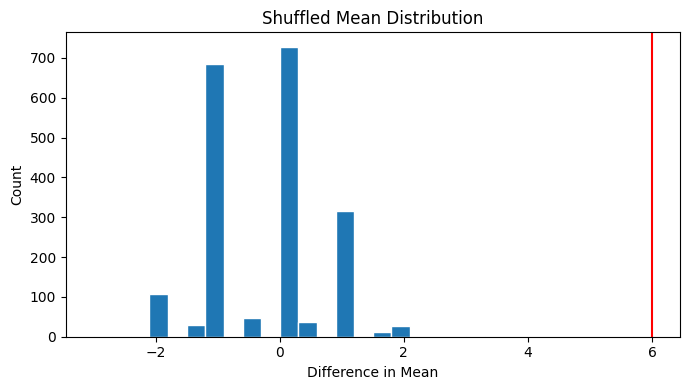

In [224]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(stored, bins=30, edgecolor='white')
ax.axvline(x=med_Woman,color="red")
ax.set_xlabel('Difference in Mean')
ax.set_ylabel('Count')
ax.set_title('Shuffled Mean Distribution')
plt.tight_layout()
plt.show()

In [214]:
stored_array=np.array(stored)
count_positive=(stored_array >= med_Woman).sum()
count_negative=(stored_array <= -1 * med_Woman).sum()
p_value=(count_positive+count_negative)/len(stored)
p_value

np.float64(0.0004725897920604915)

In [215]:
stored=[med_Man]
gender_sim=for_sim['Flagged_Man'].tolist()

In [216]:
for _ in range(999):
    np.random.shuffle(gender_sim)
    for_sim['Flagged_Man']=gender_sim
    diff=diff_med(for_sim,'Flagged_Man')
    stored.append(diff)

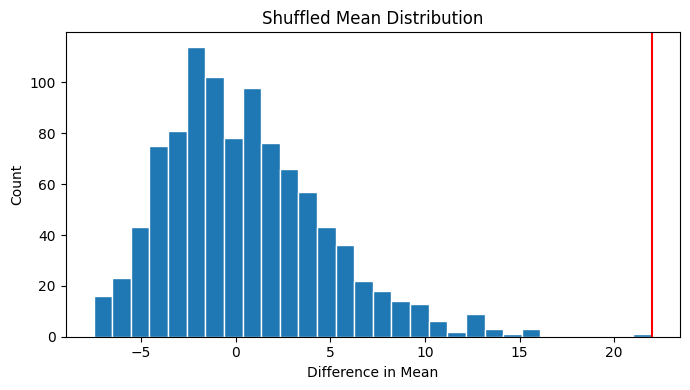

In [217]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(stored, bins=30, edgecolor='white')
ax.axvline(x=med_Man,color="red")
ax.set_xlabel('Difference in Mean')
ax.set_ylabel('Count')
ax.set_title('Shuffled Mean Distribution')
plt.tight_layout()
plt.show()

In [218]:
stored_array=np.array(stored)
count_positive=(stored_array >= med_Man).sum()
count_negative=(stored_array <= -1 * med_Man).sum()
p_value=(count_positive+count_negative)/len(stored)
p_value

np.float64(0.001)

There is a strong relationship that marriage that involved grooming (flagged) ended up lasting longer that marriage that did not involve grooming. There are more records of girls and women suseptable to grooming than men and boys.
This dataset does not account for couples that are still married.